# Predição de mortalidade neonatal no RJ com dados abertos (SINASC × SIM, 2017–2024) — v2

**Disciplina:** Introdução ao Aprendizado de Máquina para a Saúde (UFF, 2026.2).

**Artigo de referência:** Batista AFM, Diniz CSG, Bonilha EA, Kawachi I, Chiavegatto Filho ADP.
*Neonatal mortality prediction with routinely collected data: a machine learning approach.*
BMC Pediatrics 21:322 (2021).

**Perguntas:**
1. O desempenho do artigo (XGBoost, AUROC 0,971) se reproduz no estado do RJ só com
   microdados públicos, que não trazem identificadores?
2. Quanto se perde com um modelo que usa apenas informações disponíveis na admissão para o parto?
3. O modelo é calibrado e funciona igualmente por raça/cor e escolaridade da mãe e entre capital e interior?

**Versão 2:** as seções 1–5 são o projeto da disciplina (v1, tag `v1.0`); a seção 6 acrescenta o aprofundamento
para publicação (perguntas Q1–Q7 de um revisor).

Este notebook é a Parte 2 (Demonstração) do projeto e executa o fluxo inteiro:
download → linkage → pré-processamento → ajuste → avaliação → figuras.

## 1. Dependências do ambiente de execução
As versões exatas estão em `requirements.txt`. Para reproduzir:
```bash
uv venv .venv && uv pip install --python .venv/bin/python -r requirements.txt
.venv/bin/python -m src.experimento        # ≈ 1 h com 32 núcleos; grava data/resultados.pkl
.venv/bin/jupyter nbconvert --to notebook --execute --inplace notebook/mortalidade_neonatal_rj.ipynb
```
O experimento pesado (busca de hiperparâmetros, bootstrap e SHAP) roda em `src/experimento.py`.
O notebook reaproveita o resultado gravado e só executa o experimento se esse arquivo não existir.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import lightgbm, optuna, shap, sklearn, xgboost
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import precision_recall_curve, roc_curve

from src import download, evaluate, experimento, linkage, models, preprocess

FIG = RAIZ / "figuras"
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)

# Paleta categórica validada (slots 1–3 passam em todos os pares, inclusive daltonismo).
COR = {"LR": "#2a78d6", "XGBoost": "#eb6834", "LightGBM": "#1baf7a"}
TINTA, TINTA2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.6, "lines.linewidth": 2,
    "font.size": 10, "legend.frameon": False,
})
NOME_CONJ = {"A_completo": "A · completo", "B_pre_parto": "B · pré-parto"}
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| lightgbm", lightgbm.__version__, "| optuna", optuna.__version__, "| shap", shap.__version__)

/home/clebinho/uff/mestrado/terceira_opcao/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


pandas 3.0.6 | scikit-learn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0 | optuna 5.0.0 | shap 0.52.0


## 2. Carregamento do dataset
São 8 arquivos do SINASC (`DNRJ2017–2024.dbc`) e 9 do SIM (`DORJ2017–2025.dbc`), baixados do FTP público do
DATASUS: <ftp://ftp.datasus.gov.br/dissemin/publicos/>.
- O SIM vai até 2025 para incluir os óbitos de quem nasceu no fim de 2024.
- O SIM 2025 ainda é **preliminar** (pasta `SIM/PRELIM`) e só contribui com esses óbitos.
- O download é idempotente: arquivos já baixados são reaproveitados.

In [2]:
arquivos = download.baixar_tudo(RAIZ / "data" / "raw")
nv_bruto = download.carregar("DN", download.ANOS_NASCIMENTO, RAIZ / "data" / "raw")
do_bruto = download.carregar("DO", download.ANOS_OBITO, RAIZ / "data" / "raw")
print(f"SINASC: {len(nv_bruto):,} nascidos vivos, {nv_bruto.shape[1]} colunas")
print(f"SIM:    {len(do_bruto):,} óbitos, {do_bruto.shape[1]} colunas")
print("NUMERODN nos arquivos públicos?", "NUMERODN" in nv_bruto, "NUMERODN" in do_bruto)

SINASC: 1,560,938 nascidos vivos, 63 colunas
SIM:    1,379,826 óbitos, 89 colunas
NUMERODN nos arquivos públicos? False False


## 3. Pré-processamento
### 3.1 Linkage SINASC × SIM sem identificadores
Os arquivos públicos não trazem o número da DN. A Declaração de Óbito de menores de 1 ano repete dados
do nascimento, e o pareamento usa essa redundância:
- chaves compostas em cascata, da mais restritiva à mais tolerante a campos ausentes;
- em cada passada, só pares 1:1 são aceitos.

Para estimar os falsos pares, usamos campos que nunca entram nas chaves (escolaridade da mãe e perdas
fetais anteriores). A concordância na passada 1 serve de referência para pares verdadeiros, e a
concordância entre pares aleatórios com a mesma data e o mesmo sexo serve de referência para o acaso.

In [3]:
for i, chave in enumerate(linkage.PASSADAS, 1):
    print(i, " + ".join(chave))

1 DTNASC + SEXO + CODMUNRES + PESO + IDADEMAE + SEMAGESTAC + GRAVIDEZ + PARTO
2 DTNASC + SEXO + CODMUNRES + PESO + IDADEMAE
3 DTNASC + SEXO + CODMUNRES + PESO + CODESTAB
4 DTNASC + SEXO + PESO + IDADEMAE
5 DTNASC + SEXO + CODMUNRES + IDADEMAE + SEMAGESTAC
6 DTNASC + SEXO + CODMUNRES + CODESTAB + IDADEMAE


In [4]:
R = experimento.carregar() if experimento.RESULTADOS.exists() else experimento.rodar()
rel = R["linkage"]
print(f"Óbitos neonatais no SIM: {rel['n_obitos']:,} · pareados: {rel['n_pareados']:,} "
      f"({100 * rel['n_pareados'] / rel['n_obitos']:.1f}%)")
rel["por_ano"]

Óbitos neonatais no SIM: 13,471 · pareados: 12,155 (90.2%)


,nascidos_vivos,obitos_neonatais_sim,obitos_pareados,pct_pareado,tmn_sim_por_mil,tmn_pareada_por_mil
DTNASC,,,,,,
2017,223224,1914,1720,89.9,8.57,7.71
2018,220499,1837,1638,89.2,8.33,7.43
2019,207989,1817,1652,90.9,8.74,7.94
2020,199124,1744,1543,88.5,8.76,7.75
2021,189866,1627,1464,90.0,8.57,7.71
2022,180369,1523,1388,91.1,8.44,7.70
2023,176145,1577,1444,91.6,8.95,8.20
2024,163722,1432,1306,91.2,8.75,7.98


In [5]:
rel["falsos_pares"]

,n_pares,conc_ESCMAE,falsos_ESCMAE,acaso_ESCMAE,conc_QTDFILMORT,falsos_QTDFILMORT,acaso_QTDFILMORT
1,6043,79.2,0.0,40.3,90.2,0.0,60.4
2,3917,77.0,6.0,40.3,87.7,8.0,60.4
3,846,67.1,31.0,40.3,85.2,17.0,60.4
4,479,74.8,12.0,40.3,85.3,16.0,60.4
5,547,73.8,14.0,40.3,86.7,12.0,60.4
6,323,70.9,21.0,40.3,83.4,22.0,60.4


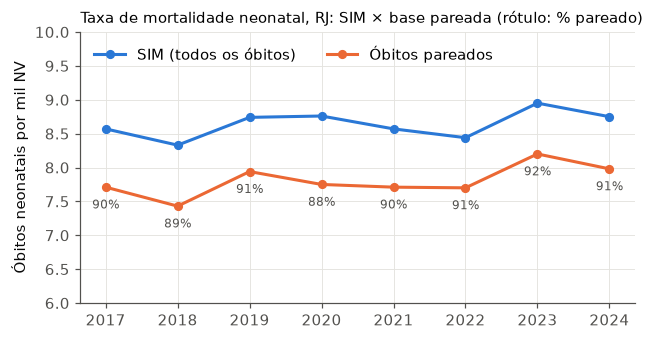

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
pa = rel["por_ano"]
ax.plot(pa.index, pa["tmn_sim_por_mil"], marker="o", ms=5, color=COR["LR"], label="SIM (todos os óbitos)")
ax.plot(pa.index, pa["tmn_pareada_por_mil"], marker="o", ms=5, color=COR["XGBoost"], label="Óbitos pareados")
for x, y, t in zip(pa.index, pa["tmn_pareada_por_mil"], pa["pct_pareado"]):
    ax.annotate(f"{t:.0f}%", (x, y), textcoords="offset points", xytext=(0, -14), ha="center",
                fontsize=8, color=TINTA2)
ax.set_ylim(6, 10); ax.set_ylabel("Óbitos neonatais por mil NV")
ax.set_title("Taxa de mortalidade neonatal, RJ: SIM × base pareada (rótulo: % pareado)", loc="left", fontsize=10)
ax.legend(loc="upper left", ncol=2)
fig.savefig(FIG / "linkage_por_ano.png")

### 3.2 Limpeza, exclusões e variáveis
- **Numéricas:** códigos de "ignorado" (99, ou 9999 no peso) viram ausentes. Mantemos idade da mãe e
  do pai, histórico obstétrico, semanas de gestação, consultas e mês de início do pré-natal, Apgar e peso.
- **Categóricas:** o "9" (ignorado) e o campo vazio viram categorias próprias, porque o não
  preenchimento da DN também informa sobre a qualidade da assistência.
- **Exclusão do artigo:** idade gestacional fora de 15–45 semanas. Nenhum registro do RJ caiu nela,
  porque o SINASC já valida esse campo.
- **Imputação e encoding:** para o XGBoost e o LightGBM, os ausentes e as categorias são tratados
  nativamente pelas árvores. Na regressão logística, imputação pela mediana com indicador de ausência,
  padronização e one-hot são ajustados só no treino.

In [7]:
R["fluxo"]

,Etapa,n
0,"Nascidos vivos residentes no RJ, 2017–2024",1560938
1,Com data de nascimento válida,1560938
2,Idade gestacional entre 15 e 45 semanas (ou au...,1560938


In [8]:
base = pd.read_parquet(RAIZ / "data" / "base_analitica.parquet")
print("Conjunto A (completo):", len(preprocess.VARS_COMPLETO), "variáveis")
print("Conjunto B (pré-parto):", len(preprocess.VARS_PRE_PARTO), "variáveis:",
      ", ".join(preprocess.ROTULOS[v] for v in preprocess.VARS_PRE_PARTO))
aus = (base[[*preprocess.NUMERICAS]].isna().mean() * 100).round(1).rename(preprocess.ROTULOS)
print("\n% ausente nas numéricas:\n", aus.sort_values(ascending=False).to_string())

Conjunto A (completo): 28 variáveis
Conjunto B (pré-parto): 17 variáveis: Idade da mãe, Idade do pai, Filhos vivos, Perdas fetais/abortos, Gestações anteriores, Partos vaginais anteriores, Cesáreas anteriores, Semanas de gestação, Consultas de pré-natal, Mês de início do pré-natal, Estado civil da mãe, Escolaridade da mãe, Tipo de gravidez, Raça/cor da mãe, Apresentação, Adequação do pré-natal (Kotelchuck), Residente na capital

% ausente nas numéricas:
 Idade do pai                  54.7
Mês de início do pré-natal     6.3
Consultas de pré-natal         2.2
Perdas fetais/abortos          2.1
Cesáreas anteriores            1.8
Partos vaginais anteriores     1.7
Apgar 1º min                   1.4
Filhos vivos                   1.3
Semanas de gestação            1.1
Apgar 5º min                   1.1
Gestações anteriores           0.9
Idade da mãe                   0.0
Peso ao nascer                 0.0


### 3.3 Estatística descritiva
Taxa de mortalidade neonatal (TMN, por mil nascidos vivos) nas principais variáveis da DN.

In [9]:
def tmn(df, col, rotulos=None):
    g = df.groupby(col, observed=True)["obito_neonatal"].agg(["size", "sum", "mean"])
    g.columns = ["NV", "óbitos", "TMN (‰)"]
    g["TMN (‰)"] *= 1000
    return g.rename(index=rotulos) if rotulos else g

faixa_peso = pd.cut(base["PESO"], [0, 1500, 2500, 4000, 8000], right=False,
                    labels=["< 1.500 g", "1.500–2.499 g", "2.500–3.999 g", "≥ 4.000 g"])
faixa_ig = pd.cut(base["SEMAGESTAC"], [0, 32, 37, 42, 46], right=False,
                  labels=["< 32 sem", "32–36 sem", "37–41 sem", "≥ 42 sem"])
desc = pd.concat({
    "Peso ao nascer": tmn(base.assign(f=faixa_peso), "f"),
    "Idade gestacional": tmn(base.assign(f=faixa_ig), "f"),
    "Apgar 5º min < 7": tmn(base.assign(f=np.where(base["APGAR5"] < 7, "sim", "não")), "f"),
    "Anomalia congênita": tmn(base, "IDANOMAL", {"1": "sim", "2": "não", "9": "ignorado", "ausente": "ausente"}),
    "Raça/cor da mãe": tmn(base, "raca_mae"),
    "Escolaridade da mãe": tmn(base, "escol_mae"),
})
desc.to_csv(FIG / "descritiva_tmn.csv")
desc

NV  óbitos  TMN (‰)
Peso ao nascer      < 1.500 g                    25466    7268  285.400
                    1.500–2.499 g               123814    2136   17.252
                    2.500–3.999 g              1335475    2600    1.947
                    ≥ 4.000 g                    76156     151    1.983
Idade gestacional   < 32 sem                     26081    6836  262.107
                    32–36 sem                   150762    2306   15.296
                    37–41 sem                  1342386    2726    2.031
                    ≥ 42 sem                     23810      48    2.016
Apgar 5º min < 7    não                        1543957    6965    4.511
                    sim                          16981    5190  305.636
Anomalia congênita  sim                          11365    1573  138.407
                    não                        1505610   10229    6.794
                    ignorado                     34862     282    8.089
                    ausente                       9101      71    7.801
Raça/cor da mãe     Amarela                       5725      57    9.956
                    Branca                      514385    3308    6.431
                    Ignorada                     26650     227    8.518
                    Indígena                      1401      10    7.138
                    Parda                       793587    6488    8.176
                    Preta                       219190    2065    9.421
Escolaridade da mãe Fund. incompleto ou menos   362104    3404    9.401
                    Ignorada                     25161     224    8.903
                    Médio                       834071    6567    7.873
                    Superior                    339602    1960    5.771

### 3.4 Amostras de treino, validação e teste (validação temporal)
| Uso | Anos | Papel |
|---|---|---|
| Ajuste | 2017–2022 | treino dos modelos |
| Validação | 2023 | busca de hiperparâmetros (Optuna), *early stopping*, recalibração isotônica e escolha do limiar |
| Teste | 2024 | avaliação final, usada uma única vez |

O esquema espelha o do artigo, que treinou em 2012–2016 e testou em 2017. A pergunta avaliada é se um
modelo treinado no passado funciona no ano seguinte.

In [10]:
pd.DataFrame(R["amostras"]).T

,n,óbitos,TMN (‰)
ajuste 2017–2022,1.221e+06,9405.0,7.702
validação 2023,1.761e+05,1444.0,8.198
teste 2024,1.637e+05,1306.0,7.977


## 4. Modelos
**Regressão logística:** $P(y=1\mid\mathbf{x}) = \sigma(\beta_0 + \boldsymbol\beta^\top\mathbf{x})$, com
$\sigma(z) = 1/(1+e^{-z})$. Ajuste por máxima verossimilhança com penalização L2 ($C$ escolhido na validação) e
`class_weight="balanced"`.

**XGBoost / LightGBM:** $F(\mathbf{x}) = \sum_{k=1}^{K} f_k(\mathbf{x})$, em que cada $f_k$ é uma árvore de regressão, e
$P(y=1\mid\mathbf{x}) = \sigma(F(\mathbf{x}))$. As árvores entram em sequência, e a árvore $k$ minimiza a expansão
de 2ª ordem da log-loss mais $\Omega(f) = \gamma T + \tfrac12\lambda\lVert w\rVert^2 + \alpha\lVert w\rVert_1$.

**Peso de classe (`scale_pos_weight`):** é tratado como hiperparâmetro, com três opções: nenhum,
$\sqrt{n_0/n_1}$ ou $n_0/n_1$. Como qualquer peso distorce as probabilidades, uma **regressão isotônica**
ajustada em 2023 recalibra as saídas. Ela é monótona, então não altera a ordenação.

**Complexidade:** o XGBoost com histogramas custa $O(K \cdot n \cdot d)$ por ajuste ($K$ árvores, $n$ registros,
$d$ variáveis), e a predição custa $O(K \cdot \text{profundidade})$ por registro. A regressão logística custa
$O(n \cdot d')$ por iteração do L-BFGS, com $d'$ colunas após o one-hot.

### 4.1 Hiperparâmetros
A busca bayesiana (TPE, Optuna) teve 30 tentativas para o XGBoost e 20 para o LightGBM. O objetivo
foi a AUPRC na validação de 2023, com *early stopping* de 50 árvores.

In [11]:
params = pd.DataFrame({f"{NOME_CONJ[c]} · {m}": pd.Series(v) for (c, m), v in R["params"].items()})
params.to_csv(FIG / "hiperparametros.csv")
params

,A · completo · LR,A · completo · XGBoost,A · completo · LightGBM,B · pré-parto · LR,B · pré-parto · XGBoost,B · pré-parto · LightGBM
C,1.0,NaN,NaN,0.01,NaN,NaN
colsample_bytree,NaN,0.774,0.881,NaN,0.774,0.881
gamma,NaN,0.014,NaN,NaN,0.014,NaN
learning_rate,NaN,0.036,0.068,NaN,0.036,0.068
max_depth,NaN,5.000,NaN,NaN,5.000,NaN
min_child_samples,NaN,NaN,113.000,NaN,NaN,113.000
min_child_weight,NaN,1.573,NaN,NaN,1.573,NaN
n_arvores,NaN,247.000,243.000,NaN,407.000,168.000
num_leaves,NaN,NaN,17.000,NaN,NaN,17.000
reg_alpha,NaN,0.002,NaN,NaN,0.002,NaN


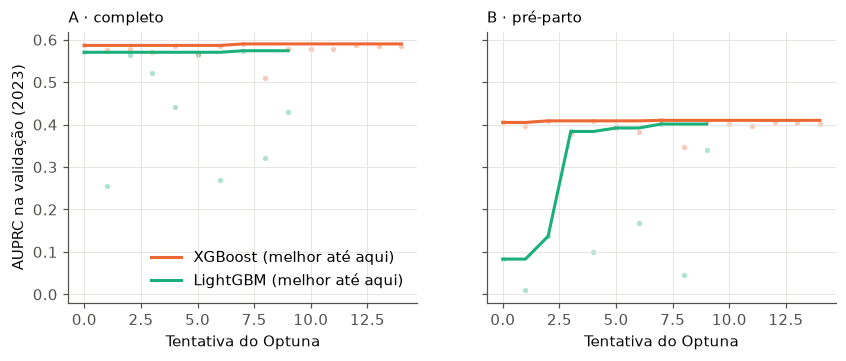

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, conj in zip(axes, preprocess.CONJUNTOS):
    for nome, cor in [("XGBoost", COR["XGBoost"]), ("LightGBM", COR["LightGBM"])]:
        t = R["estudos"][(conj, nome)]
        ax.plot(t["number"], t["value"].cummax(), color=cor, label=f"{nome} (melhor até aqui)")
        ax.scatter(t["number"], t["value"], s=12, color=cor, alpha=0.35, linewidths=0)
    ax.set_title(NOME_CONJ[conj], loc="left", fontsize=10); ax.set_xlabel("Tentativa do Optuna")
axes[0].set_ylabel(f"AUPRC na validação ({preprocess.ANO_VALIDACAO})"); axes[0].legend(loc="lower right")
fig.savefig(FIG / "optuna.png")

## 5. Execução
### 5.1 Curvas por iteração (XGBoost final)
Log-loss e AUPRC a cada árvore, no ajuste (2017–2022) e na validação (2023). A linha vertical marca a
árvore escolhida pelo *early stopping*. Log-loss e AUPRC ficam em painéis separados porque têm escalas diferentes.

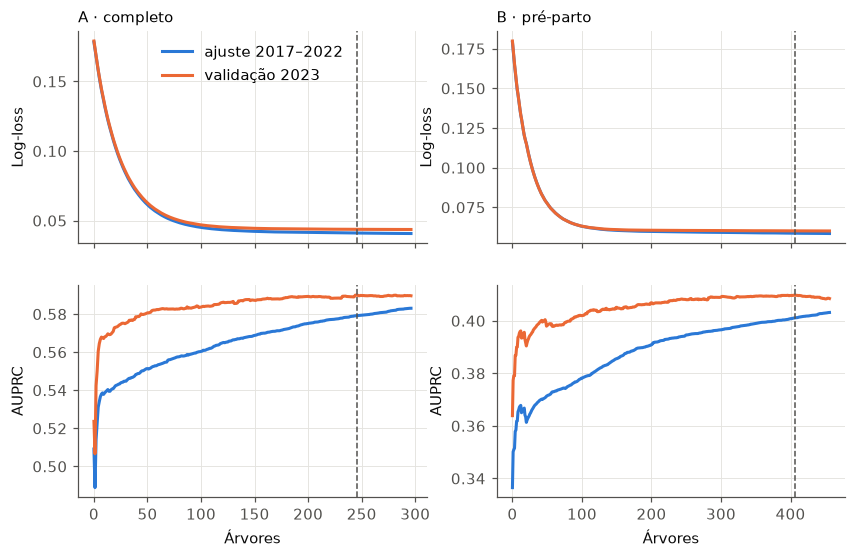

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5.5), sharex="col")
for j, conj in enumerate(preprocess.CONJUNTOS):
    c = R["curvas"][conj]
    melhor = R["params"][(conj, "XGBoost")]["n_arvores"] - 1
    for i, (met, rot) in enumerate([("logloss", "Log-loss"), ("aucpr", "AUPRC")]):
        ax = axes[i, j]
        ax.plot(c.index, c[f"treino_{met}"], color=COR["LR"], label=f"ajuste {download.ANOS_NASCIMENTO[0]}–{preprocess.ANO_VALIDACAO - 1}")
        ax.plot(c.index, c[f"valid_{met}"], color=COR["XGBoost"], label=f"validação {preprocess.ANO_VALIDACAO}")
        ax.axvline(melhor, color=TINTA2, lw=1, ls="--")
        ax.set_ylabel(rot)
        if i == 0:
            ax.set_title(NOME_CONJ[conj], loc="left", fontsize=10)
        else:
            ax.set_xlabel("Árvores")
axes[0, 0].legend()
fig.savefig(FIG / "curvas_iteracao.png")

### 5.2 Desempenho no teste (2024)
O limiar de classificação foi escolhido em 2023 para maximizar o F1 e só depois aplicado a 2024. Os IC 95%
vêm de 500 reamostras bootstrap estratificadas.

A regressão isotônica é monótona, mas é uma função em degraus e cria empates. Por isso as métricas de
**ordenação** (AUROC, AUPRC e óbitos no top 5%) usam o escore bruto do modelo. As métricas que dependem do
**valor** da probabilidade (Brier, O/E e as métricas no limiar) usam a probabilidade recalibrada.

In [14]:
def tabela_metricas(R):
    linhas = []
    for (conj, nome), t in R["metricas"].items():
        linha = {"Conjunto": NOME_CONJ[conj], "Modelo": nome}
        for m, r in t.iterrows():
            linha[m] = f"{r.valor:.3f} ({r.ic_inf:.3f}–{r.ic_sup:.3f})"
        linhas.append(linha)
    return pd.DataFrame(linhas).set_index(["Conjunto", "Modelo"])

tab = tabela_metricas(R)
tab.to_csv(FIG / "metricas_teste.csv")
tab.T

Conjunto                 A · completo                                                  B · pré-parto                                          
Modelo                             LR              XGBoost             LightGBM                   LR              XGBoost             LightGBM
AUROC             0.963 (0.956–0.969)  0.964 (0.958–0.970)  0.964 (0.958–0.970)  0.886 (0.874–0.896)  0.891 (0.879–0.902)  0.890 (0.879–0.901)
AUPRC             0.551 (0.526–0.579)  0.603 (0.577–0.628)  0.580 (0.552–0.608)  0.366 (0.338–0.394)  0.390 (0.360–0.418)  0.396 (0.367–0.424)
Brier             0.005 (0.005–0.005)  0.005 (0.004–0.005)  0.005 (0.004–0.005)  0.006 (0.006–0.006)  0.006 (0.006–0.006)  0.006 (0.006–0.006)
F1                0.554 (0.534–0.574)  0.604 (0.583–0.625)  0.596 (0.573–0.617)  0.450 (0.429–0.471)  0.454 (0.432–0.476)  0.457 (0.435–0.481)
Precisão          0.534 (0.514–0.556)  0.597 (0.576–0.620)  0.610 (0.586–0.633)  0.434 (0.411–0.455)  0.470 (0.446–0.494)  0.466 (0.441–0.490)
Sensibilidade     0.577 (0.549–0.600)  0.610 (0.583–0.636)  0.583 (0.556–0.608)  0.467 (0.442–0.492)  0.440 (0.413–0.464)  0.448 (0.423–0.474)
Especificidade    0.996 (0.996–0.996)  0.997 (0.996–0.997)  0.997 (0.997–0.997)  0.995 (0.995–0.995)  0.996 (0.996–0.996)  0.996 (0.996–0.996)
VPN               0.997 (0.996–0.997)  0.997 (0.997–0.997)  0.997 (0.996–0.997)  0.996 (0.996–0.996)  0.995 (0.995–0.996)  0.996 (0.995–0.996)
Óbitos no top 5%  0.880 (0.863–0.896)  0.880 (0.862–0.897)  0.877 (0.858–0.896)  0.705 (0.680–0.728)  0.714 (0.690–0.736)  0.710 (0.685–0.734)
O/E               0.931 (0.909–0.954)  0.954 (0.931–0.979)  0.941 (0.917–0.965)  0.953 (0.931–0.979)  0.958 (0.935–0.983)  0.967 (0.945–0.992)

**Comparação com o artigo (XGBoost, conjunto completo):**

In [15]:
artigo = {"AUROC": 0.971, "AUPRC": 0.586, "F1": 0.548, "Precisão": 0.729, "Sensibilidade": 0.440,
          "Especificidade": 0.99, "VPN": 0.997, "Óbitos no top 5%": 0.90}
nosso = R["metricas"][("A_completo", "XGBoost")]
comp = pd.DataFrame({"Batista et al. (SP, 2017)": artigo, f"Este trabalho (RJ, {preprocess.ANO_TESTE})": nosso["valor"]}).loc[list(artigo)]
comp.to_csv(FIG / "comparacao_artigo.csv")
comp.round(3)

,"Batista et al. (SP, 2017)","Este trabalho (RJ, 2024)"
AUROC,0.971,0.964
AUPRC,0.586,0.603
F1,0.548,0.604
Precisão,0.729,0.597
Sensibilidade,0.440,0.610
Especificidade,0.990,0.997
VPN,0.997,0.997
Óbitos no top 5%,0.900,0.880


In [16]:
pd.DataFrame(R["deltas"]).T

,delta,ic_inf,ic_sup,p_bilateral
XGBoost A − B (AUROC),0.074,6.389e-02,0.084,0.000
"XGBoost − LR, A_completo (AUROC)",0.001,-6.509e-04,0.003,0.184
"XGBoost − LR, B_pre_parto (AUROC)",0.005,-2.619e-04,0.011,0.064
XGBoost A − B (AUPRC),0.214,1.911e-01,0.241,0.000
"XGBoost − LR, A_completo (AUPRC)",0.052,3.975e-02,0.066,0.000
"XGBoost − LR, B_pre_parto (AUPRC)",0.024,1.109e-02,0.041,0.000


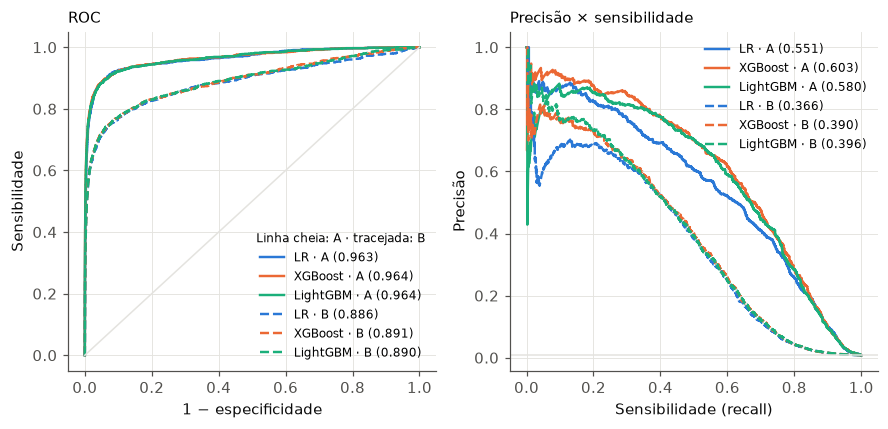

In [17]:
y_te = R["y_teste"]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
for (conj, nome), pr in R["predicoes"].items():
    p = pr["bruto"]  # curvas de ordenação: escore bruto (a isotônica cria empates)
    ls = "-" if conj == "A_completo" else "--"
    fpr, tpr, _ = roc_curve(y_te, p)
    prec, rec, _ = precision_recall_curve(y_te, p)
    auc = R["metricas"][(conj, nome)].loc["AUROC", "valor"]
    ap = R["metricas"][(conj, nome)].loc["AUPRC", "valor"]
    axes[0].plot(fpr, tpr, ls=ls, color=COR[nome], lw=1.6, label=f"{nome} · {NOME_CONJ[conj][0]} ({auc:.3f})")
    axes[1].plot(rec, prec, ls=ls, color=COR[nome], lw=1.6, label=f"{nome} · {NOME_CONJ[conj][0]} ({ap:.3f})")
axes[0].plot([0, 1], [0, 1], color=GRADE, lw=1)
axes[0].set(xlabel="1 − especificidade", ylabel="Sensibilidade", title="ROC")
axes[1].axhline(y_te.mean(), color=GRADE, lw=1)
axes[1].set(xlabel="Sensibilidade (recall)", ylabel="Precisão", title="Precisão × sensibilidade")
axes[0].legend(title="Linha cheia: A · tracejada: B", fontsize=8, title_fontsize=8, loc="lower right")
axes[1].legend(fontsize=8, loc="upper right")
for ax in axes:
    ax.title.set_fontsize(10); ax.title.set_ha("left"); ax.title.set_x(0)
fig.savefig(FIG / "roc_pr.png")

**Captura de óbitos por fração da população priorizada.** Ao ordenar os recém-nascidos pelo risco
previsto, a curva mostra que fração dos óbitos está entre os x% de maior risco. O artigo reporta mais de
90% dos óbitos nos 5% de maior risco.

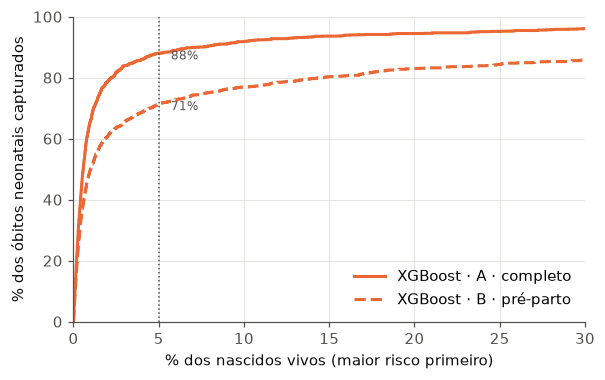

In [18]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for conj, ls in [("A_completo", "-"), ("B_pre_parto", "--")]:
    p = R["predicoes"][(conj, "XGBoost")]["bruto"]
    ordem = np.argsort(-p, kind="stable")
    capt = np.cumsum(y_te[ordem]) / y_te.sum()
    frac = np.arange(1, len(p) + 1) / len(p)
    ax.plot(frac * 100, capt * 100, ls=ls, color=COR["XGBoost"], label=f"XGBoost · {NOME_CONJ[conj]}")
    i5 = int(0.05 * len(p)) - 1
    ax.annotate(f"{capt[i5] * 100:.0f}%", (5, capt[i5] * 100), textcoords="offset points",
                xytext=(8, -4), fontsize=8, color=TINTA2)
ax.axvline(5, color=TINTA2, lw=1, ls=":")
ax.set(xlim=(0, 30), ylim=(0, 100), xlabel="% dos nascidos vivos (maior risco primeiro)",
       ylabel="% dos óbitos neonatais capturados")
ax.legend(loc="lower right")
fig.savefig(FIG / "captura_top.png")

### 5.3 Calibração
Observado × previsto por decil de risco no teste, antes e depois da recalibração isotônica. A escala é
logarítmica porque o risco vai de menos de 0,1% a mais de 50%. O/E é a razão entre óbitos observados e
esperados, e o ideal é 1.

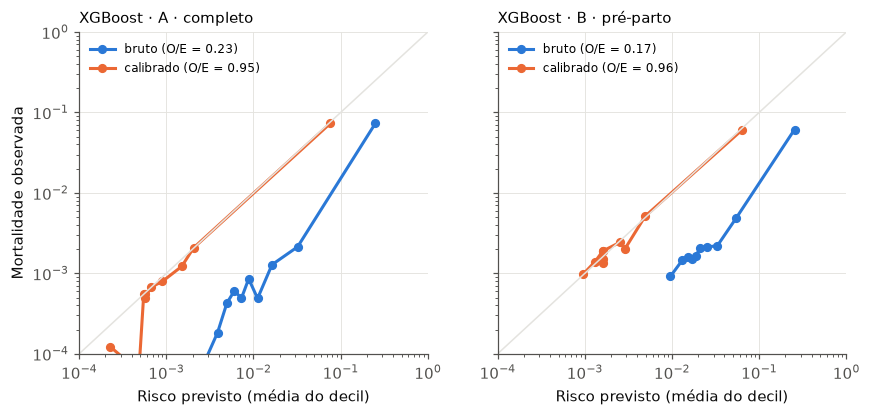

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, conj in zip(axes, preprocess.CONJUNTOS):
    cal = R["calibracao"][conj]
    for tipo, cor in [("bruto", COR["LR"]), ("calibrado", COR["XGBoost"])]:
        t = cal[tipo]
        ax.plot(t["previsto"], t["observado"], marker="o", ms=5, color=cor,
                label=f"{tipo} (O/E = {cal[f'OE_{tipo}']:.2f})")
    lim = [1e-4, 1]
    ax.plot(lim, lim, color=GRADE, lw=1)
    ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="Risco previsto (média do decil)")
    ax.set_title(f"XGBoost · {NOME_CONJ[conj]}", loc="left", fontsize=10)
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("Mortalidade observada")
fig.savefig(FIG / "calibracao.png")

### 5.4 Interpretação (SHAP)
Os valores SHAP (TreeSHAP exato, seção 5.10) foram calculados numa amostra de 20.000 nascimentos de 2024. O
gráfico mostra a importância média |SHAP| das 12 principais variáveis. No artigo, as cinco primeiras
foram Apgar 5, peso, Apgar 1, anomalia congênita e idade gestacional.

,A · completo,B · pré-parto
0,Peso ao nascer,Semanas de gestação
1,Apgar 5º min,Consultas de pré-natal
2,Apgar 1º min,Escolaridade da mãe
3,Semanas de gestação,Apresentação
4,Anomalia congênita,Raça/cor da mãe


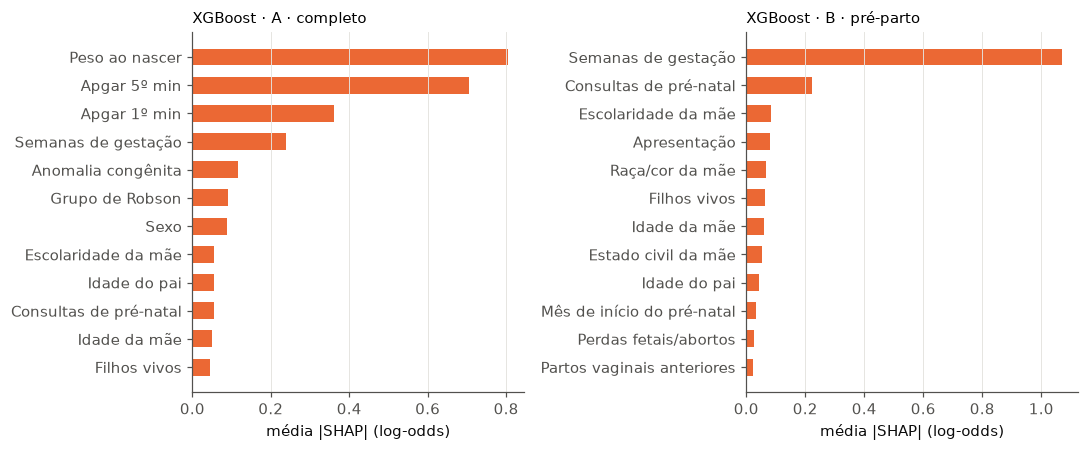

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
imp_todas = {}
for ax, conj in zip(axes, preprocess.CONJUNTOS):
    s = R["shap"][conj]
    imp = pd.Series(np.abs(s["valores"]).mean(0), index=s["X"].columns).rename(preprocess.ROTULOS)
    imp = imp.sort_values().tail(12)
    imp_todas[conj] = imp[::-1]
    ax.barh(imp.index, imp.values, color=COR["XGBoost"], height=0.6)
    ax.set_title(f"XGBoost · {NOME_CONJ[conj]}", loc="left", fontsize=10)
    ax.set_xlabel("média |SHAP| (log-odds)"); ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "shap_importancia.png")
pd.DataFrame({NOME_CONJ[c]: v.index[:5].tolist() for c, v in imp_todas.items()})

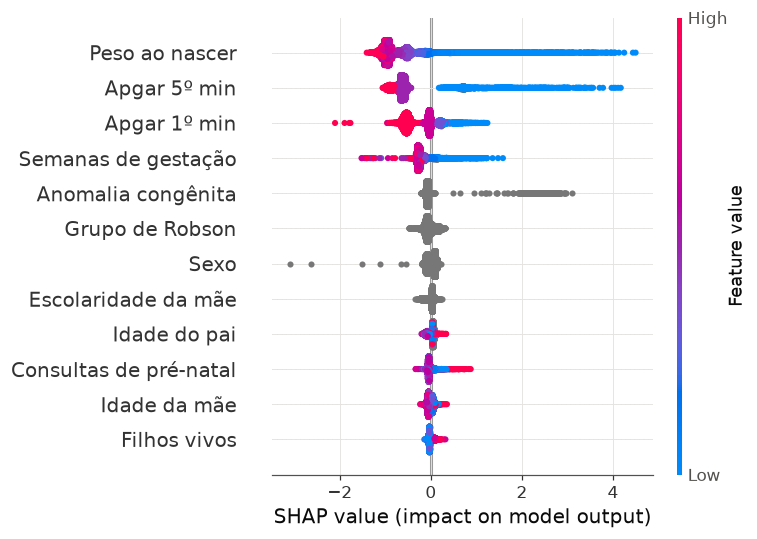

In [21]:
s = R["shap"]["A_completo"]
shap.summary_plot(s["valores"], s["X"].rename(columns=preprocess.ROTULOS), max_display=12, show=False,
                  plot_size=(7, 5))
plt.gcf().savefig(FIG / "shap_beeswarm_A.png")
plt.show()

### 5.5 Subgrupos: discriminação e calibração
Resultados do XGBoost recalibrado no teste de 2024, com IC 95% de 500 reamostras bootstrap dentro de cada
subgrupo. Subgrupos com menos de 20 óbitos (mães amarelas e indígenas) foram omitidos. Se os IC se
sobrepõem, a diferença entre os subgrupos não é distinguível do acaso.

In [22]:
teste = base[base["ano"] == preprocess.ANO_TESTE]
assert (teste["obito_neonatal"].to_numpy() == y_te).all()  # mesma ordem das predições gravadas
GRUPOS = {"raca_mae": "Raça/cor da mãe", "escol_mae": "Escolaridade da mãe", "capital": "Residência"}
ORDEM = {"raca_mae": ["Branca", "Parda", "Preta"],
         "escol_mae": ["Fund. incompleto ou menos", "Médio", "Superior"], "capital": ["Capital", "Interior"]}
sub = []
for conj in preprocess.CONJUNTOS:
    pr = R["predicoes"][(conj, "XGBoost")]
    d = teste[list(GRUPOS)].assign(y=y_te, p=pr["calibrado"], escore=pr["bruto"])
    d["capital"] = d["capital"].map({1.0: "Capital", 0.0: "Interior"})
    for g in GRUPOS:
        t = evaluate.por_subgrupo(d, g, col_escore="escore", n_bootstrap=500).rename(columns={g: "Subgrupo"})
        sub.append(t.assign(Conjunto=NOME_CONJ[conj], Variável=GRUPOS[g]))
sub = pd.concat(sub).set_index(["Conjunto", "Variável", "Subgrupo"])
sub.to_csv(FIG / "subgrupos.csv")
sub.round(3)

n  óbitos  TMN (‰)  AUROC  AUPRC    O/E  AUROC_inf  AUROC_sup  O/E_inf  O/E_sup
Conjunto      Variável            Subgrupo                                                                                                       
A · completo  Raça/cor da mãe     Branca                      53840     380    7.058  0.976  0.623  0.981      0.966      0.983    0.910    1.053
                                  Parda                       79716     645    8.091  0.957  0.592  0.948      0.946      0.967    0.899    1.008
                                  Preta                       27759     262    9.438  0.962  0.627  0.924      0.946      0.976    0.841    1.006
              Escolaridade da mãe Fund. incompleto ou menos   30504     305    9.999  0.950  0.545  0.989      0.932      0.965    0.902    1.077
                                  Médio                       92406     757    8.192  0.961  0.601  0.952      0.953      0.970    0.894    0.999
                                  Superior                    39603     235    5.934  0.980  0.681  0.917      0.970      0.989    0.844    0.998
              Residência          Capital                     57457     438    7.623  0.966  0.590  0.910      0.954      0.976    0.847    0.972
                                  Interior                   106265     868    8.168  0.963  0.613  0.977      0.955      0.970    0.933    1.024
B · pré-parto Raça/cor da mãe     Branca                      53840     380    7.058  0.898  0.415  1.022      0.877      0.919    0.942    1.110
                                  Parda                       79716     645    8.091  0.878  0.372  0.933      0.860      0.898    0.875    1.001
                                  Preta                       27759     262    9.438  0.906  0.418  0.942      0.878      0.929    0.853    1.030
              Escolaridade da mãe Fund. incompleto ou menos   30504     305    9.999  0.875  0.346  0.995      0.846      0.897    0.900    1.091
                                  Médio                       92406     757    8.192  0.885  0.389  0.951      0.869      0.900    0.880    1.009
                                  Superior                    39603     235    5.934  0.902  0.446  0.943      0.872      0.928    0.850    1.053
              Residência          Capital                     57457     438    7.623  0.885  0.392  0.944      0.863      0.906    0.867    1.016
                                  Interior                   106265     868    8.168  0.894  0.389  0.965      0.880      0.907    0.915    1.021

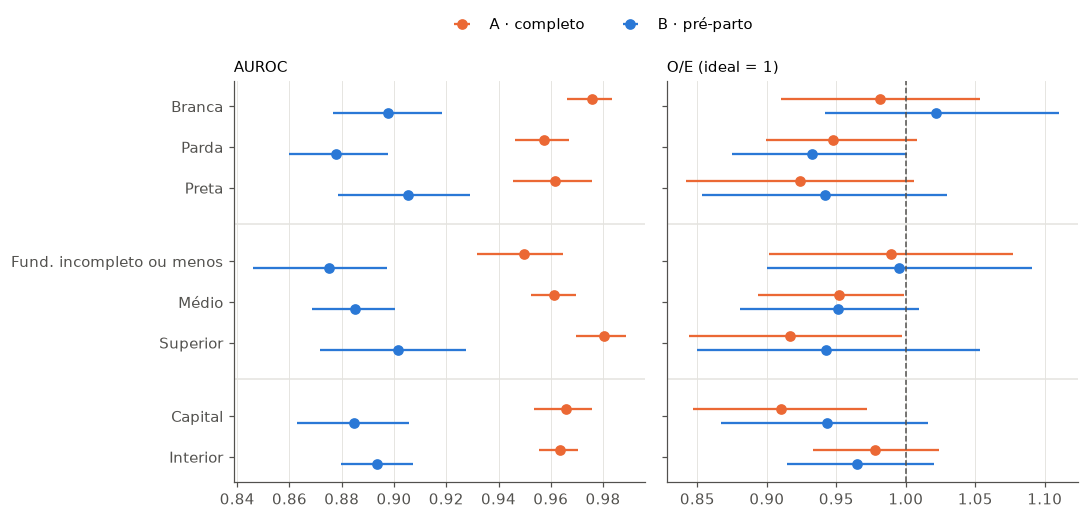

In [23]:
linhas = [(GRUPOS[g], nome) for g in GRUPOS for nome in ORDEM[g]]
ypos, y, rotulos, blocos = {}, 0, [], []
for i, (var, nome) in enumerate(linhas):
    if i and var != linhas[i - 1][0]:
        y += 0.8  # espaço entre blocos
        blocos.append(y - 0.9)
    ypos[(var, nome)] = y; rotulos.append(nome); y += 1
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
for ax, met, ref in [(axes[0], "AUROC", None), (axes[1], "O/E", 1.0)]:
    for conj, cor, desl in [("A · completo", COR["XGBoost"], -0.17), ("B · pré-parto", COR["LR"], 0.17)]:
        t = sub.loc[conj]
        yy = [ypos[k] + desl for k in t.index]
        ax.errorbar(t[met], yy, xerr=[t[met] - t[f"{met}_inf"], t[f"{met}_sup"] - t[met]], fmt="o", ms=6,
                    color=cor, ecolor=cor, elinewidth=1.5, capsize=0, label=conj)
    if ref:
        ax.axvline(ref, color=TINTA2, lw=1, ls="--")
    for yb in blocos:
        ax.axhline(yb, color=GRADE, lw=1)
    ax.set_title(met + (" (ideal = 1)" if ref else ""), loc="left", fontsize=10); ax.grid(axis="y", visible=False)
axes[0].set_yticks(list(ypos.values()), rotulos); axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2, bbox_to_anchor=(0.55, 1.03))
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIG / "subgrupos.png")

### 5.6 Calibração fraca: intercepto e inclinação
Seguimos Van Calster et al. (2019).
- **Intercepto** (*calibration-in-the-large*): ideal 0; um valor positivo indica que o modelo subestima o risco.
- **Inclinação:** ideal 1; um valor menor que 1 indica previsões extremas demais.

A TMN de cada amostra aparece abaixo. Se ela muda entre o treino e o teste (*drift*), isso desloca
o O/E para cima de 1 mesmo num modelo bem calibrado no passado.

In [24]:
C = R["complementares"]
cal_tab = pd.DataFrame({(NOME_CONJ[c], t): v for c, d in C["calibracao"].items() for t, v in d.items()}).T
cal_tab.to_csv(FIG / "calibracao_intercepto_inclinacao.csv")
print("TMN por amostra (‰):", {k: round(v, 2) for k, v in C["tmn_por_amostra"].items()})
cal_tab.round(3)

TMN por amostra (‰): {'ajuste 2017–2022': np.float64(7.7), 'validação 2023': np.float64(8.2), 'teste 2024': np.float64(7.98)}


intercepto  intercepto_inf  intercepto_sup  inclinacao  inclinacao_inf  inclinacao_sup
A · completo  bruto          -2.456          -2.526          -2.387       1.058           1.029           1.088
              calibrado      -0.082          -0.154          -0.011       1.009           0.981           1.037
B · pré-parto bruto          -2.410          -2.473          -2.347       1.016           0.990           1.043
              calibrado      -0.060          -0.124           0.004       0.979           0.954           1.005

### 5.7 Curva de calibração e utilidade clínica
- **Calibração** (painel da esquerda): mortalidade observada × prevista em 20 faixas de risco (quantis), em
  escala log, para a probabilidade bruta e a recalibrada. Intercepto e inclinação são calibração "fraca"; a
  curva é o nível recomendado por Van Calster et al.
- **Curva de decisão** (painel da direita): benefício líquido $NB(p_t) = \frac{VP}{n} - \frac{FP}{n}\cdot\frac{p_t}{1-p_t}$
  (Vickers e Elkin, 2006).
  - Com prevalência de 0,8%, "tratar todos" tem benefício negativo acima de $p_t$ ≈ 0,8%, então superá-la é
    trivial. A comparação relevante é com **tratar nenhum**.
  - A faixa sombreada, 2%–10%, corresponde a aceitar de 9 a 49 falsos alarmes por óbito identificado. É uma
    faixa plausível para decidir uma transferência *in utero*, que tem custo e risco, mas é muito menos grave
    do que um óbito evitável sem UTI.

modelo  tratar todos  tratar nenhum  fração sinalizada
              limiar                                                        
A · completo  0.02     0.006        -0.012            0.0              0.046
              0.05     0.006        -0.044            0.0              0.023
              0.10     0.005        -0.102            0.0              0.014
B · pré-parto 0.02     0.005        -0.012            0.0              0.054
              0.05     0.004        -0.044            0.0              0.024
              0.10     0.003        -0.102            0.0              0.012

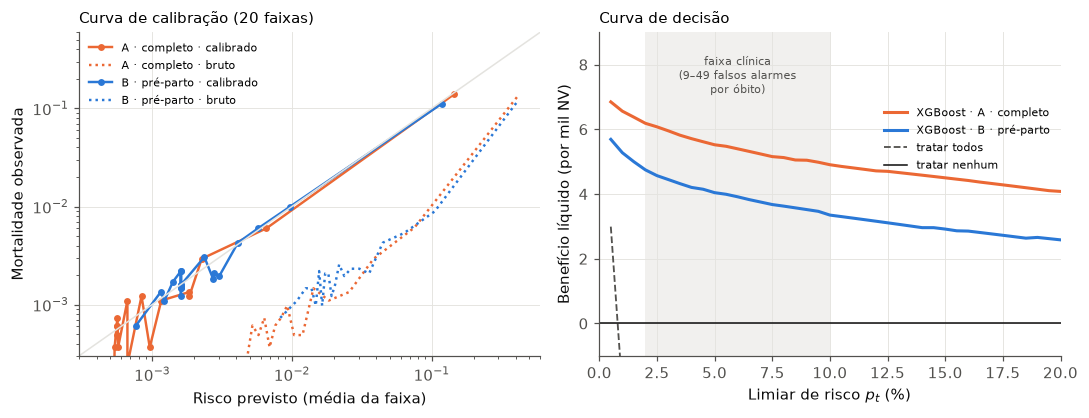

In [25]:
def curva_cal(y, p, n=20):
    d = pd.DataFrame({"y": y, "p": p})
    d["f"] = pd.qcut(d["p"].rank(method="first"), n, labels=False)
    return d.groupby("f").agg(previsto=("p", "mean"), observado=("y", "mean"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.9))
for conj, cor in [("A_completo", COR["XGBoost"]), ("B_pre_parto", COR["LR"])]:
    for t, ls, mk in [("calibrado", "-", "o"), ("bruto", ":", "")]:
        c = curva_cal(y_te, R["predicoes"][(conj, "XGBoost")][t])
        ax1.plot(c["previsto"], c["observado"], ls=ls, marker=mk, ms=3.5, color=cor, lw=1.6,
                 label=f"{NOME_CONJ[conj]} · {t}")
lim = [3e-4, 0.6]
ax1.plot(lim, lim, color=GRADE, lw=1)
ax1.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="Risco previsto (média da faixa)",
        ylabel="Mortalidade observada")
ax1.set_title("Curva de calibração (20 faixas)", loc="left", fontsize=10); ax1.legend(fontsize=7.5)
ax2.axvspan(2, 10, color=GRADE, alpha=0.5, lw=0)
for conj, cor in [("A_completo", COR["XGBoost"]), ("B_pre_parto", COR["LR"])]:
    d = C["decisao"][conj]; d = d[d["limiar"] <= 0.2]
    ax2.plot(d["limiar"] * 100, d["modelo"] * 1000, color=cor, label=f"XGBoost · {NOME_CONJ[conj]}")
d = C["decisao"]["A_completo"]; d = d[d["limiar"] <= 0.2]
ax2.plot(d["limiar"] * 100, d["tratar todos"] * 1000, color=TINTA2, ls="--", lw=1.2, label="tratar todos")
ax2.axhline(0, color=TINTA, lw=1, label="tratar nenhum")
ax2.set(xlabel="Limiar de risco $p_t$ (%)", ylabel="Benefício líquido (por mil NV)", ylim=(-1, 9), xlim=(0, 20))
ax2.text(6, 8.3, "faixa clínica\n(9–49 falsos alarmes\npor óbito)", ha="center", fontsize=7.5, color=TINTA2, va="top")
ax2.set_title("Curva de decisão", loc="left", fontsize=10); ax2.legend(fontsize=7.5, loc="upper right", bbox_to_anchor=(1, 0.8))
fig.tight_layout()
fig.savefig(FIG / "calibracao_decisao.png")
pd.concat({NOME_CONJ[c]: d.set_index("limiar").loc[[0.02, 0.05, 0.1]] for c, d in C["decisao"].items()}).round(5)

### 5.8 Viés do linkage: óbitos pareados × não pareados
Os óbitos não pareados continuam na base rotulados como sobreviventes. Para ver quem eles são, comparamos as
características que a própria Declaração de Óbito informa, sem depender do pareamento. As chaves exigem peso,
idade da mãe e semanas preenchidos, então um óbito com esses campos ausentes tem menos chance de ser pareado.

In [26]:
vl = C["vies_linkage"]
vl["perfil"].to_csv(FIG / "vies_linkage_perfil.csv")
vl["por_subgrupo"].to_csv(FIG / "vies_linkage_subgrupos.csv", index=False)
vl["perfil"].round(1)

,Pareados,Não pareados
n,12155.0,1316.0
Peso ausente (%),0.8,26.8
Peso < 1.500 g (%),60.2,52.1
Peso mediano (g),1100.0,1400.0
Semanas ausentes (%),4.8,31.5
Semanas < 32 (%),59.1,51.6
Idade da mãe ausente (%),2.1,32.2
Óbito no 1º dia (%),26.5,31.6
Óbito com 7–27 dias (%),27.8,33.3
Residente na capital (%),35.0,19.6


In [27]:
vl["por_subgrupo"].round(1)

,Variável,Categoria,Óbitos,Pareados (%)
0,Residência,Capital,4515,94.3
1,Residência,Interior,8956,88.2
2,Raça/cor do recém-nascido (DO),Branca,4433,89.4
3,Raça/cor do recém-nascido (DO),Outra/ignorada,900,91.3
4,Raça/cor do recém-nascido (DO),Parda,7327,90.6
5,Raça/cor do recém-nascido (DO),Preta,811,90.5
6,Peso na DO,ausente,445,20.7
7,Peso na DO,preenchido,13026,92.6


### 5.9 Sensibilidade ao linkage
O XGBoost foi refeito com os mesmos hiperparâmetros e rótulos alternativos **no treino e na validação**.
- **Estrito:** os nascimentos pareados nas passadas 3–6 saem.
- **Pior caso:** esses nascimentos ficam, mas rotulados como sobreviventes.

A avaliação é no **mesmo teste de 2024 completo**, com os rótulos principais. Assim, a diferença de AUROC em
relação ao modelo principal pode ser testada por bootstrap pareado.

In [28]:
linhas = []
for (conj, cen), v in C["sensibilidade"].items():
    m, d = v["metricas"]["valor"], v["delta_auroc"]
    linhas.append({"Conjunto": NOME_CONJ[conj], "Cenário": cen, "Óbitos no treino": v["positivos_treino"],
                   "AUROC": m["AUROC"], "AUPRC": m["AUPRC"], "Top 5%": m["Óbitos no top 5%"], "O/E": m["O/E"],
                   "ΔAUROC vs principal": d["delta"], "IC inf": d["ic_inf"], "IC sup": d["ic_sup"]})
for conj in preprocess.CONJUNTOS:
    m = R["metricas"][(conj, "XGBoost")]["valor"]
    linhas.append({"Conjunto": NOME_CONJ[conj], "Cenário": "principal", "AUROC": m["AUROC"], "AUPRC": m["AUPRC"],
                   "Top 5%": m["Óbitos no top 5%"], "O/E": m["O/E"]})
sens = pd.DataFrame(linhas).sort_values(["Conjunto", "Cenário"]).set_index(["Conjunto", "Cenário"])
sens.to_csv(FIG / "sensibilidade_linkage.csv")
sens.round(4)

Óbitos no treino  AUROC  AUPRC  Top 5%    O/E  ΔAUROC vs principal     IC inf     IC sup
Conjunto      Cenário                                                                                            
A · completo  estrito              7661.0  0.963  0.601   0.880  1.071           -9.000e-04 -2.000e-03  1.000e-04
              pior caso            7661.0  0.963  0.599   0.882  1.156           -1.300e-03 -2.900e-03  5.000e-04
              principal               NaN  0.964  0.603   0.880  0.954                  NaN        NaN        NaN
B · pré-parto estrito              7661.0  0.891  0.392   0.711  1.105            6.000e-04 -1.500e-03  2.900e-03
              pior caso            7661.0  0.892  0.391   0.709  1.162            1.300e-03 -9.000e-04  3.400e-03
              principal               NaN  0.891  0.390   0.714  0.958                  NaN        NaN        NaN

### 5.10 Explicabilidade (XAI)
O SHAP (TreeSHAP exato) decompõe o log-odds previsto de cada nascimento em contribuições aditivas das
variáveis: $\text{logit}\,\hat p = \phi_0 + \sum_j \phi_j$. A análise tem quatro partes:
1. **Global:** importância média |SHAP| (seção 5.4).
2. **Dependência:** SHAP em função do valor da variável. O efeito aprendido faz sentido clinicamente?
3. **Local:** explicação de casos individuais, isto é, por que o modelo acertou ou errou.
4. **Estabilidade e atributos sensíveis:** o ranking muda entre algoritmos ou amostras? Quanto raça/cor e
   escolaridade pesam nas explicações?

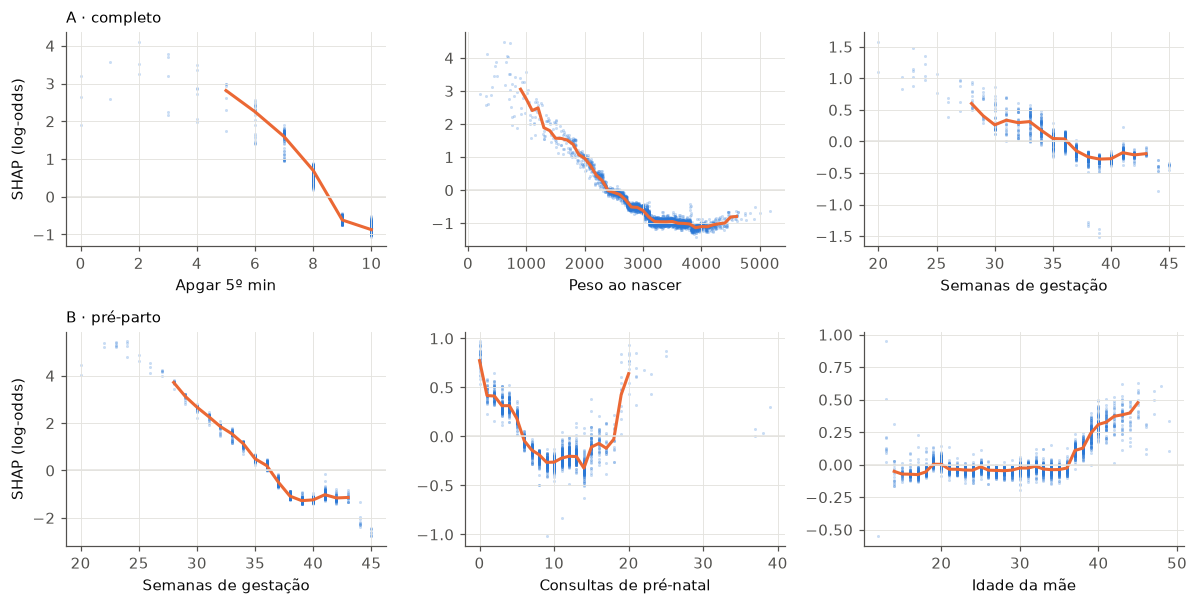

In [29]:
X_ = C["xai"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for i, conj in enumerate(preprocess.CONJUNTOS):
    for j, (v, d) in enumerate(X_["dependencia"][conj].items()):
        ax = axes[i, j]
        d = d.dropna()
        amostra = d.sample(min(6000, len(d)), random_state=0)
        ax.scatter(amostra["x"], amostra["shap"], s=4, alpha=0.25, color=COR["LR"], linewidths=0)
        m = d.groupby(d["x"].round(0 if v != "PESO" else -2))["shap"].median()
        m = m[d.groupby(d["x"].round(0 if v != "PESO" else -2)).size() >= 30]
        ax.plot(m.index, m.values, color=COR["XGBoost"], lw=2)
        ax.axhline(0, color=GRADE, lw=1)
        ax.set_xlabel(preprocess.ROTULOS[v]); ax.set_ylabel("SHAP (log-odds)" if j == 0 else "")
        ax.set_title(NOME_CONJ[conj] if j == 0 else "", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "xai_dependencia.png")

**Explicações locais.** São três casos do teste de 2024, no modelo completo: o óbito de maior risco previsto,
um óbito que o modelo não sinalizou (falso negativo mediano) e o sobrevivente de maior risco previsto (falso
positivo). O ponto de partida é o risco médio ($\phi_0$), e cada barra soma ou subtrai log-odds.

Risco de base φ0: 6.18% | erro de aditividade máx.: 1.4901161e-07


valor   shap
                    variavel                          
Verdadeiro positivo Apgar 5º min            1.0  2.309
                    Peso ao nascer        670.0  2.222
                    Anomalia congênita        1  1.130
                    Semanas de gestação    22.0  0.703
                    Apgar 1º min            1.0  0.682
                    Grupo de Robson          10  0.081
Falso negativo      Anomalia congênita        1  2.455
                    Peso ao nascer       3450.0 -1.007
                    Apgar 5º min            8.0  0.667
                    Semanas de gestação    39.0 -0.304
                    Apgar 1º min            7.0  0.298
                    Grupo de Robson           5 -0.061
Falso positivo      Peso ao nascer        385.0  2.699
                    Apgar 5º min            1.0  2.500
                    Semanas de gestação    21.0  0.922
                    Apgar 1º min            1.0  0.639
                    Idade da mãe           40.0  0.100
                    Grupo de Robson          10  0.100

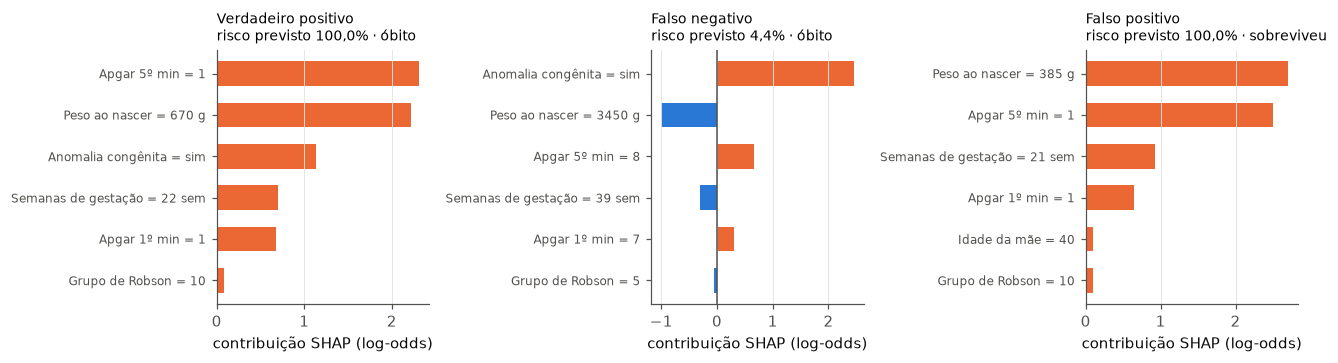

In [30]:
CODIGOS = {"Anomalia congênita": {"1": "sim", "2": "não", "9": "ignorado"},
           "Sexo": {"1": "masculino", "2": "feminino"}, "Tipo de gravidez": {"1": "única", "2": "dupla"},
           "Tipo de parto": {"1": "vaginal", "2": "cesáreo"}}


def legivel(var, valor):
    if var in CODIGOS:
        return CODIGOS[var].get(str(valor), str(valor))
    try:
        v = float(valor)
    except ValueError:
        return str(valor)
    txt = f"{v:.0f}"
    return txt + " g" if var == "Peso ao nascer" else (txt + " sem" if var == "Semanas de gestação" else txt)


loc = X_["locais"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (nome, c) in zip(axes, loc["casos"].items()):
    t = c["top"].iloc[::-1]
    rot = [f"{r.variavel} = {legivel(r.variavel, r.valor)}" for r in t.itertuples()]
    ax.barh(rot, t["shap"], color=[COR["XGBoost"] if v > 0 else COR["LR"] for v in t["shap"]], height=0.6)
    ax.axvline(0, color=TINTA2, lw=1)
    desfecho = "óbito" if c["obito"] else "sobreviveu"
    ax.set_title(f"{nome}\nrisco previsto {100 * c['prob_calibrada']:.1f}% · {desfecho}".replace(".", ","),
                 loc="left", fontsize=9)
    ax.set_xlabel("contribuição SHAP (log-odds)"); ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "xai_local.png")
print(f"Risco de base φ0: {100 * loc['base_prob']:.2f}% | erro de aditividade máx.:",
      max(c["aditividade_erro"] for c in loc["casos"].values()))
pd.concat({k: v["top"].set_index("variavel") for k, v in loc["casos"].items()}).round(3)

**Estabilidade e atributos sensíveis.**

In [31]:
est = pd.DataFrame({NOME_CONJ[c]: {k: v for k, v in e.items() if k != "importancia_lgbm"}
                    for c, e in X_["estabilidade"].items()}).T
sens_attr = pd.DataFrame({NOME_CONJ[c]: {preprocess.ROTULOS[k]: v for k, v in s_["fracao_importancia"].items()}
                          for c, s_ in X_["sensiveis"].items()}).T
est.to_csv(FIG / "xai_estabilidade.csv"); sens_attr.to_csv(FIG / "xai_sensiveis.csv")
display(est.round(3)); display((100 * sens_attr).round(1))
X_["sensiveis"]["B_pre_parto"]["RACACORMAE"].rename(index={"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda",
                                                            "5": "Indígena", "ausente": "Ignorada"}).round(3)

,spearman_xgb_lgbm,top5_comum_xgb_lgbm,spearman_metades,top5_comum_metades
A · completo,0.90,4.0,0.999,5.0
B · pré-parto,0.98,5.0,0.998,5.0


,Raça/cor da mãe,Escolaridade da mãe
A · completo,1.1,1.9
B · pré-parto,3.5,4.5


,mean,size
categoria,,
Branca,-0.108,6629
Preta,0.061,3376
Amarela,0.046,97
Parda,0.031,9686
Indígena,0.284,32
Ignorada,0.204,180


### 5.11 Avaliação das premissas
- **Colinearidade (regressão logística):** as contagens do histórico obstétrico são quase uma soma umas das
  outras (gestações ≈ partos + perdas). O VIF mede quanto isso infla a variância dos coeficientes. A
  colinearidade afeta a interpretação dos coeficientes, mas não a predição. A penalização L2 estabiliza o ajuste,
  e as árvores não dependem dessa premissa.
- **Mecanismo dos ausentes:** se a TMN difere muito entre registros com e sem o campo, a ausência não é
  aleatória (MCAR descartado). Ela é informativa, e por isso usamos indicadores de ausência ou a categoria
  "ignorado", em vez de só imputar.
- **Independência:** gêmeos compartilham mãe e gestação. Medimos quanto eles pesam e se a AUROC muda sem eles.

In [32]:
C["colinearidade"].round(2)

,VIF
Gestações anteriores,22.36
Filhos vivos,19.85
Perdas fetais/abortos,4.60
Partos vaginais anteriores,4.46
Cesáreas anteriores,2.27
Apgar 5º min,1.96
Apgar 1º min,1.95
Semanas de gestação,1.60
Idade da mãe,1.54
Peso ao nascer,1.54


In [33]:
C["ausencia"].round(2)

,Variável,Ausente (%),TMN ausente (‰),TMN preenchido (‰)
0,Idade do pai,54.68,8.79,6.57
1,Consultas de pré-natal,2.23,19.72,7.52
2,Mês de início do pré-natal,6.26,17.38,7.15
3,Semanas de gestação,1.15,13.35,7.72
4,Apgar 5º min,1.06,27.65,7.57
5,Peso ao nascer,0.00,0.00,7.79
6,Anomalia congênita (ignorado),2.82,8.03,7.78
7,Escolaridade da mãe (ignorado),1.61,8.90,7.77
8,Raça/cor da mãe (ignorado),1.71,8.52,7.77


In [34]:
pd.Series(C["gemelares"]).round(4)

% múltiplos                       2.349
% dos óbitos em múltiplos        10.184
AUROC A_completo (todos)          0.964
AUROC A_completo (só únicos)      0.963
AUROC B_pre_parto (todos)         0.891
AUROC B_pre_parto (só únicos)     0.882
dtype: float64

## 6. Parte 2 (v2): aprofundamento para publicação
A primeira parte (seções 1–5) é o projeto da disciplina. Esta parte responde às perguntas que um revisor de
revista faria, e que ficaram em aberto no parecer:

| # | Pergunta | Análise |
|---|---|---|
| Q1 | Um escore simples faz o mesmo que o XGBoost? | LR só com peso, idade gestacional e Apgar 5 (e + anomalia) |
| Q2 | Há vazamento na DN (campos preenchidos depois do óbito)? | AUROC por idade no óbito: dia 0, 1–6 e 7–27 dias |
| Q3 | Os anos de pandemia distorcem o treino? | Reajuste sem 2020–2021 |
| Q4 | O resultado depende das variáveis que também são chave do linkage? | Reajuste sem peso, idade da mãe, semanas, gravidez e parto |
| Q5 | A calibração se degrada com o tempo? | Janelas deslizantes: modelo reajustado × congelado |
| Q6 | O estimador de falsos pares acerta? | Simulação com padrão-ouro conhecido |
| Q7 | Uma etapa probabilística recupera os óbitos não pareados? | Fellegi–Sunter sobre o resíduo do determinístico |

Todas as análises usam os hiperparâmetros do experimento principal e avaliam no **mesmo teste**, com Δ por
bootstrap pareado. O código está em `src/aprofundamento.py` (`python -m src.aprofundamento`, ≈ 1 h), que
grava `data/resultados_v2.pkl`.

In [35]:
from src import aprofundamento

caminho_v2 = RAIZ / "data" / "resultados_v2.pkl"
V = aprofundamento.carregar(caminho_v2) if caminho_v2.exists() else aprofundamento.rodar(caminho_v2)
print(f"teste em {V['ano_teste']}; execução completa do aprofundamento: {V['tempo_total_s'] / 60:.0f} min")


def resumo(m):
    """Linha com AUROC, AUPRC, top 5% e O/E de uma tabela `com_ic`."""
    v = m["valor"]
    return {"AUROC": v["AUROC"], "AUPRC": v["AUPRC"], "Top 5%": v["Óbitos no top 5%"], "O/E": v["O/E"]}


def fmt_delta(d):
    return f"{d['delta']:+.4f} ({d['ic_inf']:+.4f} a {d['ic_sup']:+.4f})"


# As figuras v2_*.png e as macros do relatório v2 saem do mesmo gerador, para não divergirem.
import runpy
_ = runpy.run_path(str(RAIZ / "relatorio_v2" / "gerar_numeros_v2.py"))

teste em 2024; execução completa do aprofundamento: 18 min


134 macros -> /home/clebinho/uff/mestrado/terceira_opcao/relatorio_v2/numeros_v2.tex


### 6.1 Q1: baseline clínico simples
Se três variáveis chegam perto do XGBoost com 28, o valor do trabalho está na calibração, na equidade e no
linkage, e não no algoritmo. Um revisor vai perguntar isso; é melhor responder antes.

In [36]:
linhas = {"XGBoost (28 variáveis)": resumo(R["metricas"][("A_completo", "XGBoost")]),
          "LR (28 variáveis)": resumo(R["metricas"][("A_completo", "LR")])}
deltas = {"LR (28 variáveis)": fmt_delta(R["deltas"]["XGBoost − LR, A_completo (AUROC)"])}
for nome, b in V["baseline"].items():
    linhas[f"LR ({nome})"] = resumo(b["metricas"])
    deltas[f"LR ({nome})"] = fmt_delta(b["delta_auroc"])
tab_base = pd.DataFrame(linhas).T.assign(**{"ΔAUROC XGBoost − modelo": pd.Series(deltas)})
tab_base.to_csv(FIG / "v2_baseline.csv")
tab_base

,AUROC,AUPRC,Top 5%,O/E,ΔAUROC XGBoost − modelo
XGBoost (28 variáveis),0.964,0.603,0.880,0.954,NaN
LR (28 variáveis),0.963,0.551,0.880,0.931,+0.0013 (-0.0007 a +0.0033)
LR (peso + IG + Apgar 5),0.947,0.490,0.837,0.973,+0.0175 (+0.0126 a +0.0225)
LR (peso + IG + Apgar 5 + anomalia),0.960,0.522,0.877,0.933,+0.0045 (+0.0018 a +0.0073)


### 6.2 Q2: desempenho por idade no óbito (vazamento na DN)
A DN deveria ser preenchida no nascimento. Se campos como a anomalia congênita fossem completados depois do
óbito, o modelo acertaria desproporcionalmente os óbitos do **dia 0**, que acontecem antes do fechamento da
declaração. Cada faixa é comparada com todos os sobreviventes do teste.

In [37]:
V["idade_obito"].round(3)

,Conjunto,Faixa,Óbitos,AUROC,AUROC_inf,AUROC_sup,Top 5%
0,A_completo,dia 0,370,0.988,0.981,0.994,0.954
1,A_completo,1–6 dias,572,0.968,0.959,0.976,0.879
2,A_completo,7–27 dias,364,0.934,0.920,0.949,0.805
3,B_pre_parto,dia 0,370,0.921,0.900,0.941,0.803
4,B_pre_parto,1–6 dias,572,0.898,0.884,0.914,0.703
5,B_pre_parto,7–27 dias,364,0.848,0.824,0.874,0.640


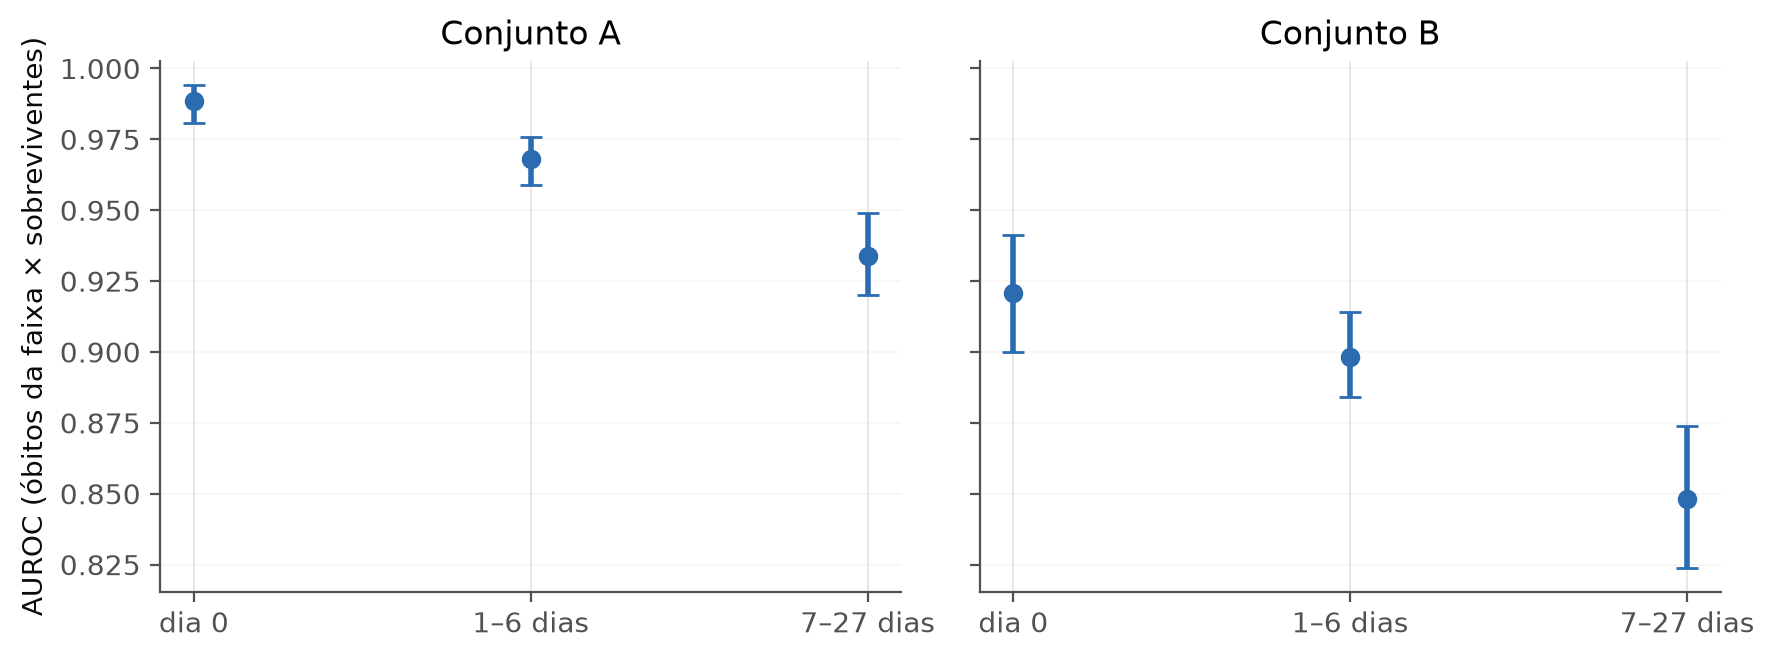

In [38]:
from IPython.display import Image
Image(filename=str(FIG / "v2_idade_obito.png")) if (FIG / "v2_idade_obito.png").exists() else None

**Teste direto pela data da declaração.** A DN registra quando foi preenchida (`DTDECLARAC`) e digitada
(`DTCADASTRO`). Dentro de cada faixa de idade no óbito, que controla a gravidade, comparamos os óbitos com DN
declarada **depois** do óbito com os demais. Se a DN "soubesse" do óbito, o primeiro grupo seria previsto
melhor, e isso deveria aparecer no modelo A (que tem Apgar e anomalia) e **não** no B.

In [39]:
dec = V["declaracao"]
dec[(dec["Campo"] == "declarada") & (dec["Faixa"] != "7–27 dias")].round(3)

,Campo,Conjunto,Faixa,DN,Óbitos,% da faixa,AUROC,AUROC_inf,AUROC_sup,Top 5%
0,declarada,A_completo,todas,depois do óbito,130,9.954,0.989,0.978,0.995,0.954
1,declarada,A_completo,todas,antes ou no dia,1176,90.046,0.962,0.956,0.968,0.872
2,declarada,A_completo,dia 0,depois do óbito,107,28.919,0.990,0.979,0.997,0.963
3,declarada,A_completo,dia 0,antes ou no dia,263,71.081,0.988,0.980,0.994,0.951
4,declarada,A_completo,1–6 dias,depois do óbito,23,4.021,0.986,0.976,0.994,0.913
5,declarada,A_completo,1–6 dias,antes ou no dia,549,95.979,0.967,0.958,0.975,0.878
8,declarada,B_pre_parto,todas,depois do óbito,130,9.954,0.934,0.902,0.958,0.777
9,declarada,B_pre_parto,todas,antes ou no dia,1176,90.046,0.886,0.874,0.896,0.707
10,declarada,B_pre_parto,dia 0,depois do óbito,107,28.919,0.931,0.901,0.963,0.804
11,declarada,B_pre_parto,dia 0,antes ou no dia,263,71.081,0.916,0.893,0.938,0.802


### 6.3 Q3 e Q4: pandemia e variáveis de chave
- **Sem pandemia:** 2020–2021 saem do ajuste; validação e teste não mudam.
- **Sem chaves:** saem peso, idade da mãe, semanas, gravidez e parto, que também definem o linkage. Uma
  queda grande mostraria que o modelo depende justamente dos campos que determinam quem ganha rótulo.

In [40]:
rob = {}
for conj in preprocess.CONJUNTOS:
    rob[(NOME_CONJ[conj], "principal")] = {**resumo(R["metricas"][(conj, "XGBoost")]), "ΔAUROC": "—", "ΔAUPRC": "—"}
    for chave, rot in [("sem_pandemia", "sem 2020–2021"), ("sem_chaves", "sem variáveis de chave")]:
        v = V[chave][conj]
        rob[(NOME_CONJ[conj], rot)] = {**resumo(v["metricas"]), "ΔAUROC": fmt_delta(v["delta_auroc"]),
                                       "ΔAUPRC": fmt_delta(v["delta_auprc"])}
tab_rob = pd.DataFrame(rob).T
tab_rob.to_csv(FIG / "v2_robustez.csv")
tab_rob

AUROC  AUPRC Top 5%    O/E                       ΔAUROC                       ΔAUPRC
A · completo  principal               0.964  0.603   0.88  0.954                            —                            —
              sem 2020–2021           0.964  0.606  0.875  0.953  -0.0001 (-0.0010 a +0.0007)  +0.0024 (-0.0022 a +0.0075)
              sem variáveis de chave  0.956  0.492  0.831  0.934  -0.0081 (-0.0107 a -0.0057)  -0.1110 (-0.1292 a -0.0955)
B · pré-parto principal               0.891   0.39  0.714  0.958                            —                            —
              sem 2020–2021           0.889  0.389  0.707  0.966  -0.0014 (-0.0045 a +0.0014)  -0.0007 (-0.0061 a +0.0043)
              sem variáveis de chave  0.801  0.085  0.417  1.015  -0.0892 (-0.0997 a -0.0787)  -0.3048 (-0.3288 a -0.2803)

### 6.4 Q5: janelas deslizantes (drift temporal)
Para cada ano de teste *t*: ajuste até *t*−2, validação em *t*−1 e teste em *t*. O modelo **reajustado** é
refeito todo ano; o **congelado** é o da primeira janela aplicado aos anos seguintes, sem reajuste nem
recalibração. A diferença entre os dois mede o custo de não atualizar o modelo.

In [41]:
V["janelas"].round(3)

,Conjunto,Modelo,Ano teste,Anos ajuste,TMN ajuste (‰),TMN teste (‰),AUROC,AUPRC,O/E,Intercepto,Inclinação
0,A_completo,reajustado,2020,2017–2018,7.568,7.749,0.955,0.521,0.953,-0.077,0.984
1,A_completo,congelado,2020,2017–2018,7.568,7.749,0.955,0.521,0.953,-0.077,0.984
2,A_completo,reajustado,2021,2017–2019,7.687,7.711,0.960,0.557,0.985,-0.025,1.014
3,A_completo,congelado,2021,2017–2019,7.687,7.711,0.959,0.552,0.936,-0.108,1.008
4,A_completo,reajustado,2022,2017–2020,7.702,7.695,0.961,0.557,0.998,-0.003,0.994
5,A_completo,congelado,2022,2017–2020,7.702,7.695,0.960,0.555,0.932,-0.116,1.008
6,A_completo,reajustado,2023,2017–2021,7.703,8.198,0.956,0.584,1.014,0.024,0.981
7,A_completo,congelado,2023,2017–2021,7.703,8.198,0.955,0.587,0.953,-0.080,1.014
8,A_completo,reajustado,2024,2017–2022,7.702,7.977,0.964,0.603,0.954,-0.082,1.009
9,A_completo,congelado,2024,2017–2022,7.702,7.977,0.962,0.599,0.906,-0.164,1.036


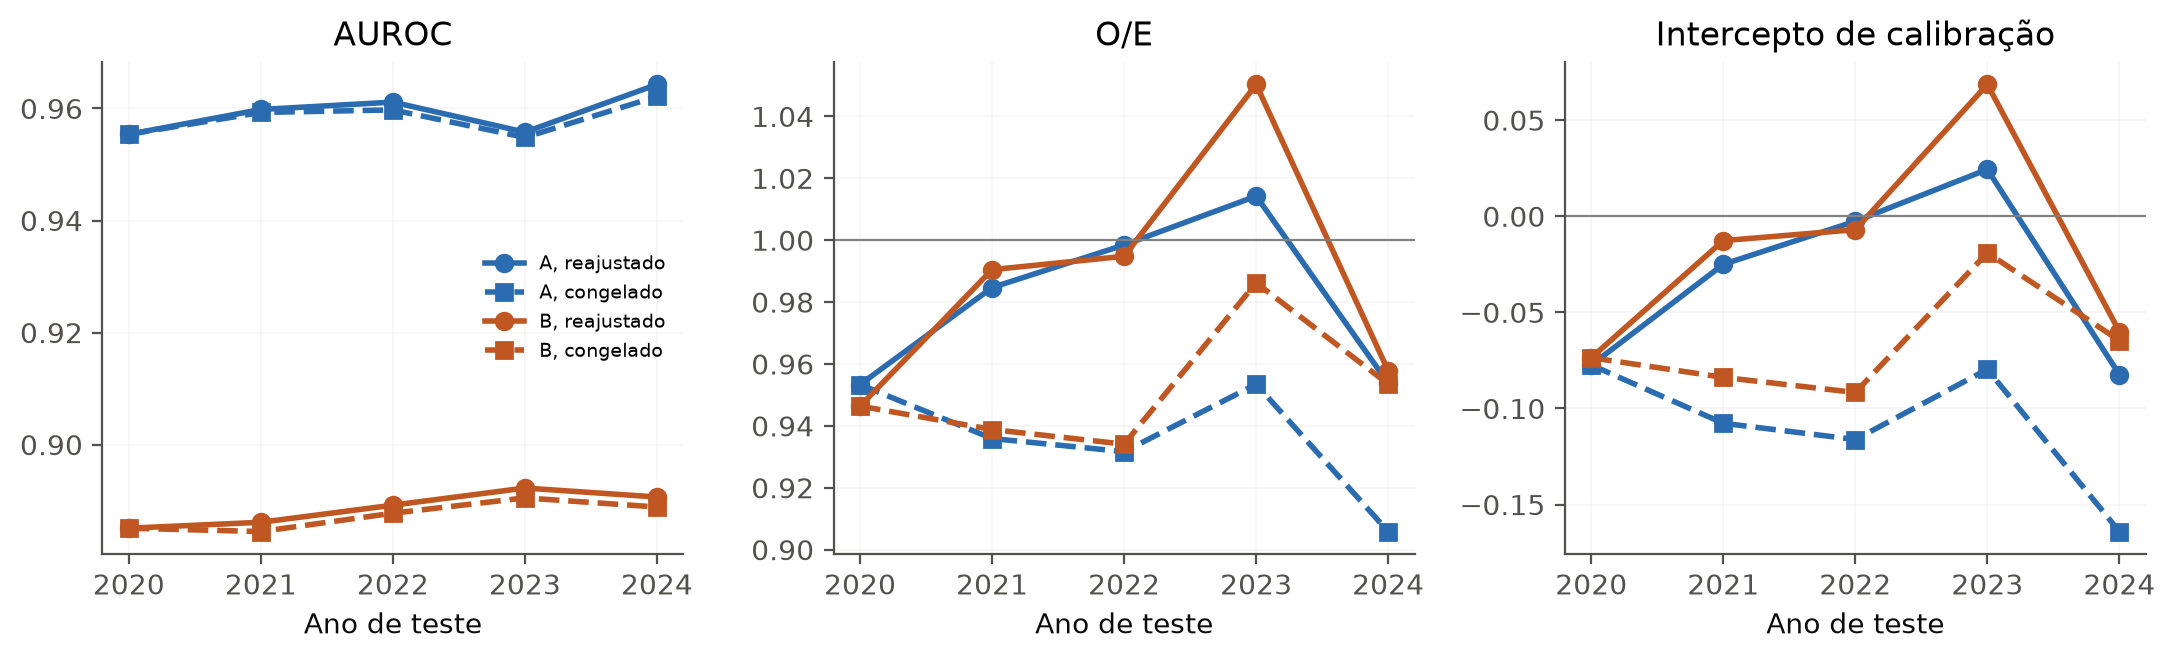

In [42]:
Image(filename=str(FIG / "v2_janelas.png")) if (FIG / "v2_janelas.png").exists() else None

### 6.5 Q6: simulação de padrão-ouro do linkage
Não temos a base identificada, então fabricamos uma verdade conhecida. As DN dos nascidos efetivamente
pareados viram "DO sintéticas", com a **ausência observada nas DO reais** e erros de digitação por campo em três
cenários (baixo, realista, alto). Dois cenários extras retiram 5% e 10% das DN verdadeiras da base
(sub-registro ou residência diferente na DN e na DO). O linkage roda sobre a base inteira, e os demais nascidos servem de
distratores. Assim medimos a fração **real** de falsos pares de cada passada e a comparamos com a **estimada**
pelo modelo de mistura usado na primeira parte.

In [43]:
S = V["simulacao"]
pd.Series(S["ausencia_do"], name="ausência na DO real").mul(100).round(1)

CODMUNRES      0.0
CODESTAB       1.0
SEXO           0.4
GRAVIDEZ       2.9
PARTO          3.9
PESO           3.3
IDADEMAE       5.0
SEMAGESTAC     7.4
ESCMAE        14.9
QTDFILMORT     9.1
Name: ausência na DO real, dtype: float64

In [44]:
comp = []
for cen in [c for c in S if c != "ausencia_do"]:
    real, est = S[cen]["real"], S[cen]["estimado"]
    for p in [i for i in real.index if i != "total"]:
        comp.append({"cenário": cen, "passada": p, "pares": int(real.loc[p, "n_pares"]),
                     "falsos reais (%)": real.loc[p, "falsos_reais"],
                     "falsos estimados (%)": est.loc[p, ["falsos_ESCMAE", "falsos_QTDFILMORT"]].mean()
                     if p in est.index else np.nan})
    comp.append({"cenário": cen, "passada": "total", "pares": int(real.loc["total", "n_pares"]),
                 "falsos reais (%)": real.loc["total", "falsos_reais"],
                 "cobertura verdadeira (%)": real.loc["total", "cobertura_verdadeira_%"],
                 "etapa FS: pares": S[cen]["fs_pares"], "etapa FS: falsos reais (%)": S[cen]["fs_falsos_reais"]})
tab_sim = pd.DataFrame(comp)
tab_sim.to_csv(FIG / "v2_simulacao.csv", index=False)
tab_sim.round(1)

,cenário,passada,pares,falsos reais (%),falsos estimados (%),cobertura verdadeira (%),etapa FS: pares,etapa FS: falsos reais (%)
0,baixo,1,8587,0.0,0.0,NaN,NaN,NaN
1,baixo,2,2196,0.0,0.5,NaN,NaN,NaN
2,baixo,3,583,0.0,3.5,NaN,NaN,NaN
3,baixo,4,98,3.1,2.0,NaN,NaN,NaN
4,baixo,5,441,0.0,1.5,NaN,NaN,NaN
5,baixo,6,81,1.2,5.0,NaN,NaN,NaN
6,baixo,total,11986,0.0,NaN,98.6,2.0,100.0
7,realista,1,7497,0.0,0.0,NaN,NaN,NaN
8,realista,2,2549,0.0,1.0,NaN,NaN,NaN
9,realista,3,658,0.2,1.5,NaN,NaN,NaN


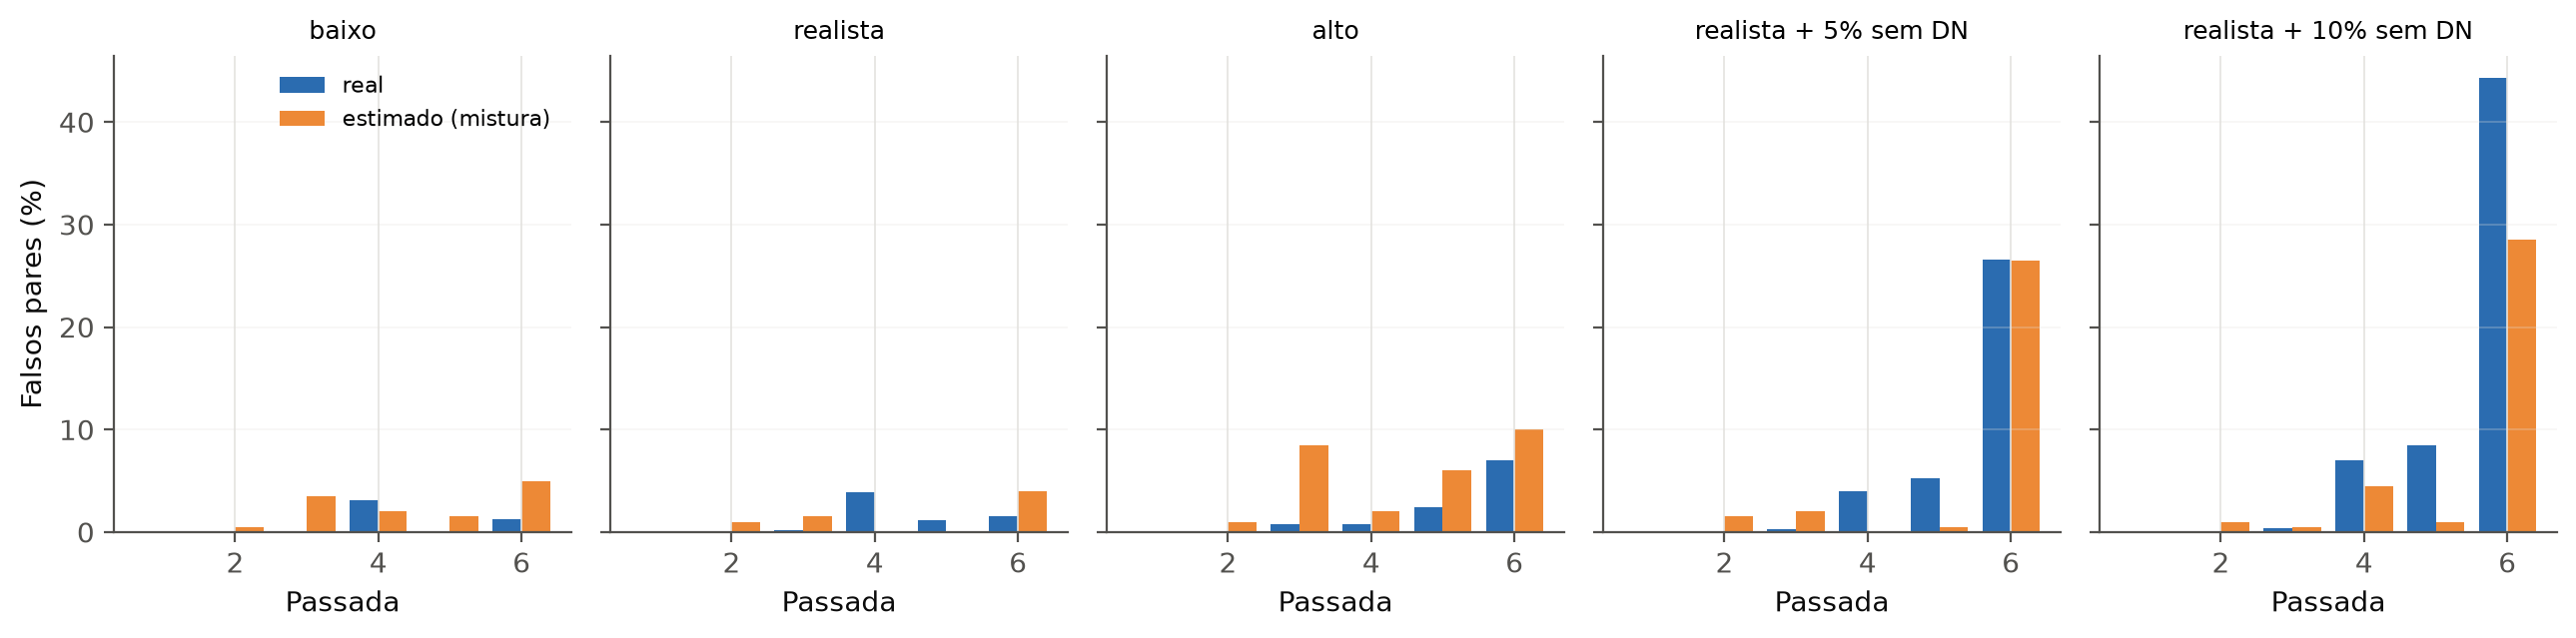

In [45]:
Image(filename=str(FIG / "v2_simulacao.png")) if (FIG / "v2_simulacao.png").exists() else None

### 6.6 Q7: etapa probabilística (Fellegi–Sunter)
Sobre os óbitos que o determinístico não pareou, comparamos cada óbito com os nascidos da mesma data e sexo
(bloqueio). Cada campo recebe um nível de concordância (exato, próximo, discorda, ausente). As probabilidades
*u* vêm de pares aleatórios do bloco; *m*, dos pares determinísticos em cujas chaves o campo não entra; e a
proporção de pares λ supõe no máximo um par verdadeiro por óbito (Fellegi e Sunter, 1969). Pares com
probabilidade a posteriori ≥ 0,9 são aceitos 1:1, do mais provável para o menos provável.

O EM, alternativa usual para estimar *m* e λ, é mostrado para comparação: num bloco com ~1 par verdadeiro em
centenas, ele convergiu para outra partição (λ dez vezes o plausível).

In [46]:
P = V["probabilistico"]
display(pd.Series({k: P[k] for k in ["n_obitos", "n_deterministico", "n_restantes", "candidatos",
                                     "n_probabilistico", "pct_total", "recuperados_no_teste"]}))
print("EM (comparação):", P["em"], "| λ usado:", round(P["parametros"]["lambda"], 5))

n_obitos                 13471.000
n_deterministico         12155.000
n_restantes               1316.000
candidatos              347020.000
n_probabilistico            13.000
pct_total                   90.327
recuperados_no_teste         0.000
dtype: float64

EM (comparação): {'n_pares': 0, 'lambda': 0.03921637146063271} | λ usado: 0.00364


In [47]:
P["falsos_estimados"]

,n_pares,conc_ESCMAE,falsos_ESCMAE,acaso_ESCMAE,conc_QTDFILMORT,falsos_QTDFILMORT,acaso_QTDFILMORT
1,6043,79.2,0.0,40.3,90.2,0.0,60.3
2,3917,77.0,6.0,40.3,87.7,8.0,60.3
3,846,67.1,31.0,40.3,85.2,17.0,60.3
4,479,74.8,12.0,40.3,85.3,16.0,60.3
5,547,73.8,14.0,40.3,86.7,12.0,60.3
6,323,70.9,21.0,40.3,83.4,22.0,60.3
7,13,58.3,54.0,40.3,66.7,79.0,60.3


In [48]:
pd.DataFrame(P["parametros"]["m"]).T.round(3).add_prefix("m_").join(
    pd.DataFrame(P["parametros"]["u"]).T.round(3).add_prefix("u_"))

,m_0,m_1,m_2,u_0,u_1,u_2
CODMUNRES,1.000,0.000,0.000,0.857,0.000,0.143
PESO,0.454,0.546,0.000,0.981,0.015,0.004
IDADEMAE,0.272,0.723,0.005,0.881,0.077,0.042
SEMAGESTAC,0.426,0.480,0.093,0.860,0.089,0.051
GRAVIDEZ,0.032,0.000,0.968,0.122,0.000,0.878
PARTO,0.059,0.000,0.941,0.489,0.000,0.511
CODESTAB,0.118,0.000,0.882,0.982,0.000,0.018


**Por que o resíduo não se recupera?** Quantos campos informativos cada óbito restante tem na DO, e qual a maior
probabilidade a posteriori entre os seus candidatos:

In [49]:
display(P["restantes_campos"].rename("óbitos restantes por nº de campos preenchidos (de 7)"))
P["post_max_faixas"].rename("óbitos por faixa da melhor probabilidade a posteriori")

1     31
2    238
3     26
4     22
5     60
6    213
7    726
Name: óbitos restantes por nº de campos preenchidos (de 7), dtype: int64

(-0.001, 0.1]    901
(0.1, 0.5]       284
(0.5, 0.9]        65
(0.9, 1.0]        13
Name: óbitos por faixa da melhor probabilidade a posteriori, dtype: int64

### 6.7 Síntese da Parte 2
| # | Resposta |
|---|---|
| Q1 | Peso + IG + Apgar 5 + anomalia chegam quase à AUROC do XGBoost; o ganho do XGBoost está na AUPRC. |
| Q2 | Sem evidência de vazamento: DN declarada depois do óbito não é prevista melhor na mesma faixa de idade, e as diferenças aparecem também no modelo B. |
| Q3 | Tirar 2020–2021 não muda o teste. |
| Q4 | O modelo A resiste sem as variáveis de chave (perde AUPRC); o B depende da idade gestacional. |
| Q5 | A discriminação é estável no tempo; a calibração deriva e exige recalibração anual. |
| Q6 | A cascata é precisa quando a DN existe; DN ausente concentra falsos pares na chave mais tolerante; o estimador de mistura é só ordem de grandeza. |
| Q7 | O resíduo não se recupera com Fellegi–Sunter: a DN provavelmente não está na base do estado. |

Os números citados no relatório v2 (`relatorio_v2/main.pdf`) saem das tabelas acima.

## 7. Conclusão
O resumo dos resultados, a discussão e as limitações estão no `README.md`, em `relatorio/main.pdf` (v1) e em
`relatorio_v2/main.pdf` (v2, com a Parte 2).
Todos os números citados nesses documentos saem das tabelas acima.

A execução completa do experimento principal levou:

In [50]:
print(f"{R['tempo_total_s'] / 60:.0f} min")

41 min
